# Generate Cloud Volume Mask

The cloud volume mask (CVM) determines a grid point to be cloudy (1) or clear (0). For tomography, it is generally best for the CVM to be clear-sky confident meaning that a grid point is only marked clear if we are confident it is clear.

In this notebook we will constrain the cloud volume using the LCL (400 m) from dropsonde measurements, MISR cloud top heights (CTH), and space carving (SC), which uses camera-by-camera cloud masks.

In [1]:
# conda env 'at3d_pure_k9'
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import sys
import at3d
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

from src.utils.util import load_sensor_dict
import src.CoordinateTransform as ct

In [2]:
cmv_mod = 'ATM'
obs_file = PROJECT_ROOT / 'data' / 'V11' / f'AT3D_OBS_bbox_O105254_P117_R00275_X17950487_18003012_Y0193187_0245712_H1400_{cmv_mod}.nc'
obs = load_sensor_dict(obs_file)

rte_grid = xr.load_dataset(PROJECT_ROOT / 'data' / 'interim' / 'RTG_default.nc')

## Lifting Condensation Level

In [3]:
lcl = 0.4 # km
lcl_cvm = np.zeros((rte_grid.sizes['x'], rte_grid.sizes['y'], rte_grid.sizes['z']))
lcl_cvm[:,:,rte_grid.z.data >= lcl] = 1
lcl_cvm = lcl_cvm.astype(int)

## Cloud Top Height

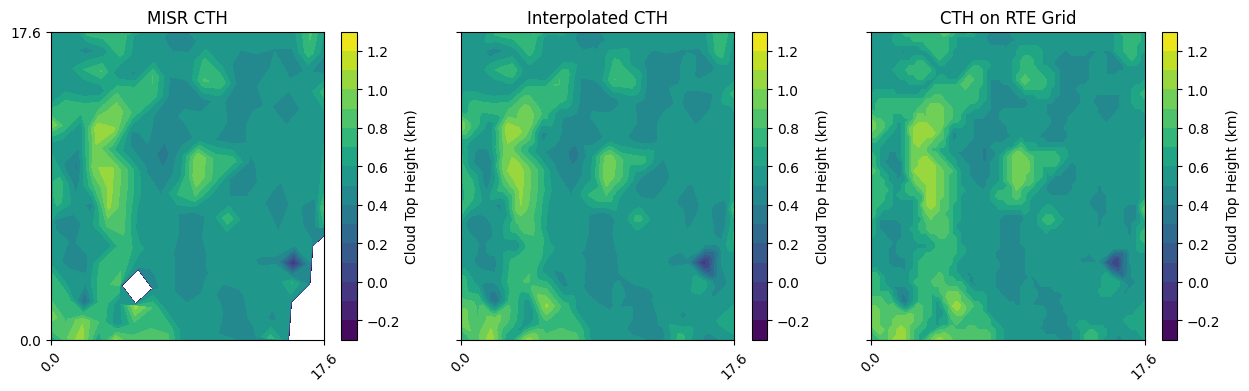

In [4]:
opacity_bias = 120 # m
# Transform SOM to AT3D coordinates
cth = xr.load_dataset(PROJECT_ROOT / 'data' / 'interim' / 'MISR_CTH_O105254_P117_R01100_X17950900_18002600_Y0193600_0245300.nc')
transform = ct.CoordinateTransform(
    17976750.0,
    219450.0,
    1.655084388740932,
    17600,
    17600
)
X, Y = np.meshgrid(cth.som_x, cth.som_y, indexing='ij')
Xp, Yp = transform.SOM2AT3D(X, Y)
cth['x'] = (['som_x', 'som_y'], Xp/1000)
cth['y'] = (['som_x', 'som_y'], Yp/1000)
cth['CloudTopHeight'] = (cth.CloudTopHeight + opacity_bias) / 1000

# Create the new grid
at3d_x, at3d_y = np.meshgrid(rte_grid.x.data, rte_grid.y.data, indexing='ij')

# Flatten the original grid and data
coarse_points = np.array([cth.x.data.flatten(), cth.y.data.flatten()]).T
coarse_cth = cth.CloudTopHeight.data.flatten()

# Mask out NaN values
mask = coarse_cth > -5
coarse_points = coarse_points[mask]
coarse_cth = coarse_cth[mask]

# Interpolate the data onto the new grid
cth_interp = griddata(coarse_points, coarse_cth, (at3d_x, at3d_y), method='linear')

cth_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, cth_interp, side='right')]

levels = np.arange(-0.3, 1.4, 0.1)
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
c0 = ax[0].contourf(cth.x.data, cth.y.data, cth.CloudTopHeight.data, levels=levels)
plt.colorbar(c0, ax=ax[0], label='Cloud Top Height (km)')
ax[0].set_title('MISR CTH')
c1 = ax[1].contourf(at3d_x, at3d_y, cth_interp, levels=levels)
plt.colorbar(c1, ax=ax[1], label='Cloud Top Height (km)')
ax[1].set_title('Interpolated CTH')
c2 = ax[2].contourf(at3d_x, at3d_y, cth_on_rte_grid, levels=levels)
plt.colorbar(c2, ax=ax[2], label='Cloud Top Height (km)')
ax[2].set_title('CTH on RTE Grid')
box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
ticks = [0.0, 17.6]
for a in ax.flatten():
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([0,17.6])
    a.set_ylim([0,17.6])

cth_on_rte_grid = np.expand_dims(cth_on_rte_grid, axis=-1)
cth_cvm = (rte_grid.z.data <= cth_on_rte_grid).astype(int)

## Space Carving

In [5]:
brf_thresholds = [0.120, 0.076, 0.054, 0.044, 0.040, 0.045, 0.052, 0.068, 0.092]
agreement = (0, 2/9)

masked_sensors = at3d.containers.SensorsDict()
for i, sensor in enumerate(obs['MISR']['sensor_list']):
    sensor_copy = sensor.copy(deep=True)
    mask = np.zeros(sensor.dims['nrays'])
    mask[sensor_copy.brf.data > brf_thresholds[i]] = 1
    sensor_copy['cloud_mask'] = (['nrays'], mask)
    masked_sensors.add_sensor('MISR', sensor_copy)

space_carver = at3d.space_carve.SpaceCarver(rte_grid, bcflag=3)
sc_cvm = space_carver.carve(masked_sensors, agreement=agreement, linear_mode=False)

In [6]:
# sc_kwargs = {
#     'y': 'z',
#     'x': 'y',
#     'col': 'x',
#     'col_wrap': 5,
#     'cmap': 'gray',
#     'vmin': 0,
#     'vmax': 1
# }
# sc_cvm.isel(x=slice(0,None,4)).mask.plot(**sc_kwargs)

## Cloud volume mask

In [7]:
cvm = rte_grid.copy(deep=True)
cvm['lcl'] = (['x','y','z'], lcl_cvm)
cvm['cth'] = (['x','y','z'], cth_cvm)
cvm['sc'] = sc_cvm.mask
cvm['encoded'] = (cvm.lcl * 1) + (cvm.cth * 2) + (cvm.sc * 4)
# Swap the 3's and 4's...
tmp = cvm.encoded.copy(deep=True).data
new_encoded = cvm.encoded.copy(deep=True).data
new_encoded[tmp == 3] = 4
new_encoded[tmp == 4] = 3
cvm['encoded'] = (['x','y','z'], new_encoded)
cvm['encoded'].attrs['description'] = '(LCL * 1) + (CTH * 2) + (SC * 4); then swap the 3s and 4s.'

cvm_df = cvm.encoded.to_dataframe()
cvm_summary = cvm_df['encoded'].value_counts().sort_index().to_frame()
cvm_summary['volume'] = cvm_summary['count'] * 0.275 * 0.275 * 0.1
cvm_summary

,count,volume
encoded,,
0,19,0.143688
1,2820,21.326250
2,2397,18.127313
4,1430,10.814375
5,29161,220.530063
6,14484,109.535250
7,13064,98.796500


In [8]:
ticks = np.arange(0,8)
labels = [
    'clear',       #0 
    'lcl cloud',   #1
    'cth cloud',   #2
    'sc cloud',    #3*
    'sc clear',    #4*
    'cth clear',   #5
    'lcl clear',   #6
    'cloud',       #7
]
# cmap = mpl.colors.ListedColormap(
#     [
#         'black',     # 000
#         'darkred',   # 001
#         'darkgreen', # 010
#         'darkblue',  # 100*
#         'yellow',    # 011*
#         'pink',      # 101
#         'cyan',      # 110
#         'white'      # 111
#     ]
# )
cmap = mpl.colors.ListedColormap(
    [
        'black',     # 000
        'darkgray',   # 001
        'darkgray', # 010
        'darkgray',  # 100*
        'lightgray',    # 011*
        'lightgray',      # 101
        'lightgray',      # 110
        'white'      # 111
    ]
)

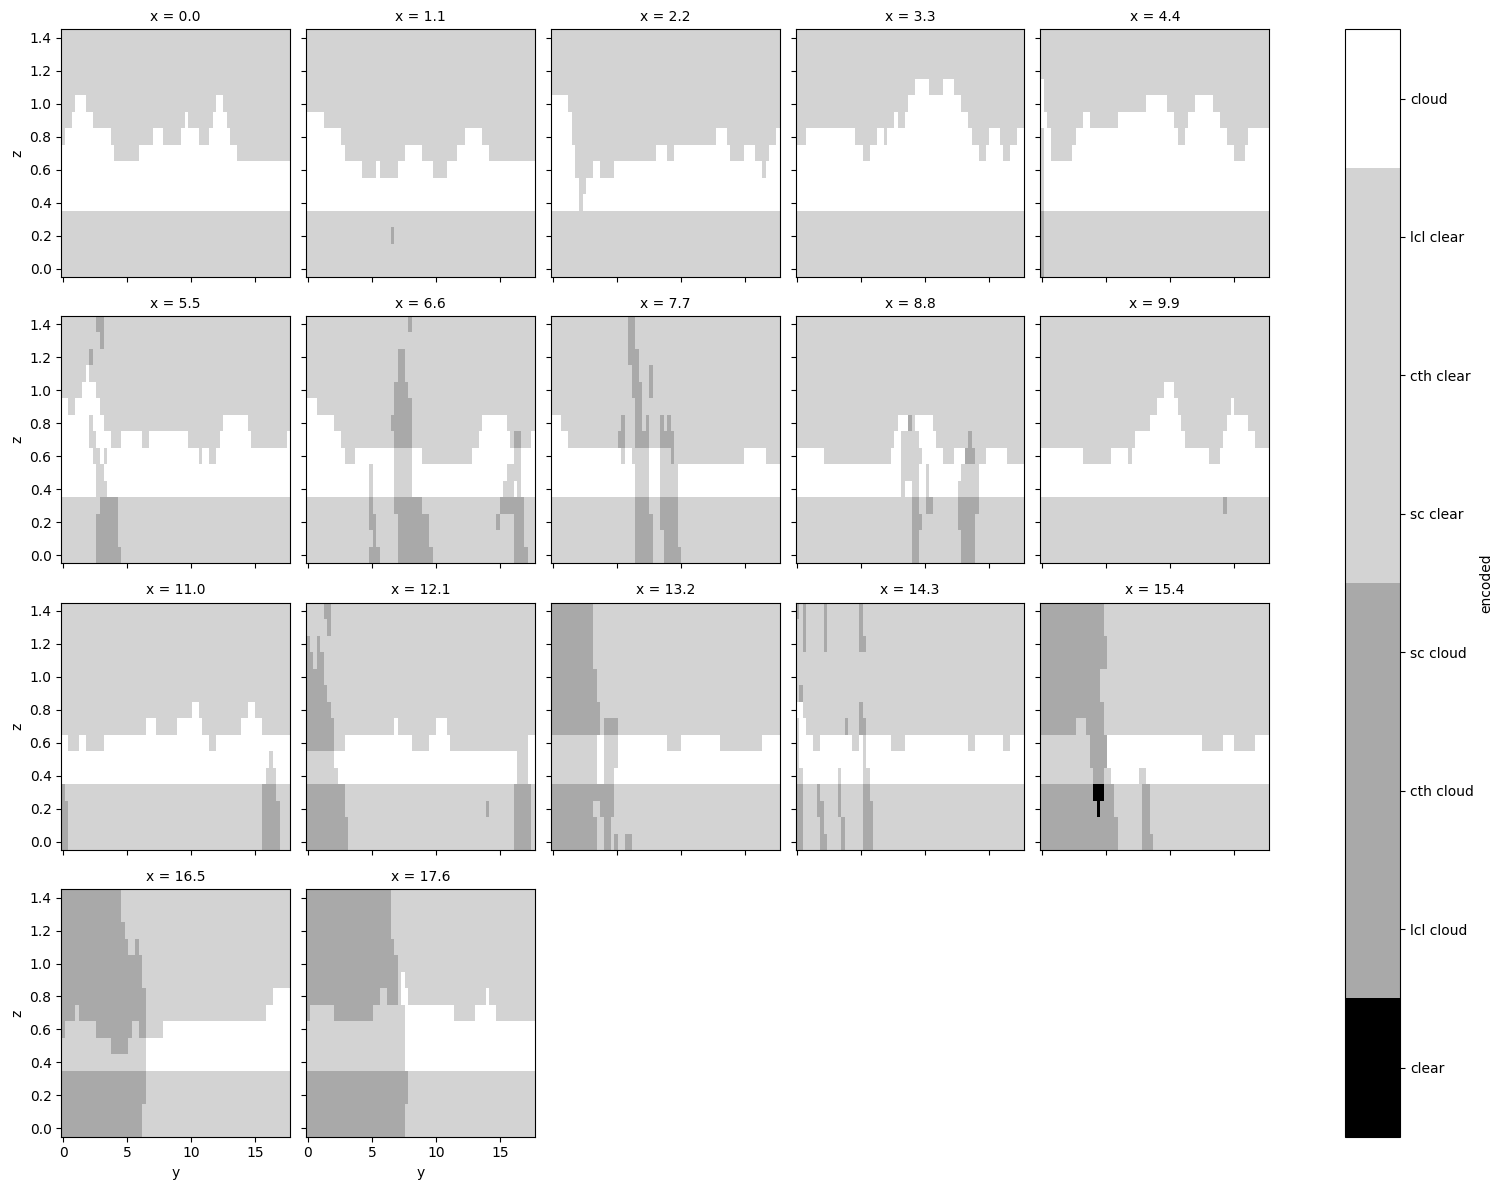

In [9]:
sc_kwargs = {
    'y': 'z',
    'x': 'y',
    'col': 'x',
    'col_wrap': 5,
    'cmap':cmap,
    'vmin': -0.5,
    'vmax': 7.5
}
fg = cvm.isel(x=slice(0,None,4)).encoded.plot(**sc_kwargs)
# fg = cvm.encoded.plot(**sc_kwargs)
c = fg.cbar.ax.set_yticks(ticks)
c = fg.cbar.ax.set_yticklabels(labels)

In [10]:
# sc_kwargs = {
#     'y': 'z',
#     'x': 'x',
#     'col': 'y',
#     'col_wrap': 10,
#     'cmap':cmap,
#     'vmin': -0.5,
#     'vmax': 7.5
# }
# fg = cvm.encoded.plot(**sc_kwargs)
# c = fg.cbar.ax.set_yticks(ticks)
# c = fg.cbar.ax.set_yticklabels(labels)

In [11]:
cvm_final = np.zeros_like(lcl_cvm)
cloud_regions = [7] # LCL & CTH & SC
# cloud_regions = [0, 1, 2, 3, 4, 5, 6, 7] # Unconstrained
# cloud_regions = [3, 5, 6, 7] # SC only

cloud_regions.sort()
for r in cloud_regions:
    cvm_final[cvm.encoded.data == r] = 1
cvm['cloud_volume_mask'] = (['x','y','z'], cvm_final.astype(int))
filename = 'CVM_LCL_CTH_SC_R' + '_'.join([str(num) for num in cloud_regions]) + f'_{cmv_mod}.nc'
outfile = PROJECT_ROOT / 'data' / 'V11' / filename
cvm.to_netcdf(outfile)

# sc_kwargs = {
#     'y': 'z',
#     'x': 'y',
#     'col': 'x',
#     'col_wrap': 10,
#     'cmap':'gray',
#     'vmin': 0,
#     'vmax': 1
# }
# fg = cvm.cloud_volume_mask.plot(**sc_kwargs)